# NFL home field advantage: COVID and stadium characteristics

This notebook answers two questions about home advantage using the cleaned game data in `data/clean/`
(1999-2025, regular season, neutral-site games removed). Each part has a figure, a short explanation of the
method, the results and what they mean.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy import stats

root = Path.cwd()
if root.name == "python":
    root = root.parent
fig_dir = root / "output" / "figures"

games = pd.read_csv(root / "data" / "clean" / "games.csv")
teams = pd.read_csv(root / "data" / "clean" / "team_seasons.csv")
stadiums = pd.read_csv(root / "data" / "raw" / "stadiums" / "stadiums.csv")

reg = games[~games["is_playoff"]].copy()
reg["home_win_score"] = reg["home_win"] + 0.5 * reg["is_tie"]  # win = 1, tie = 0.5, loss = 0
reg["home_margin"] = reg["result"]  # home points minus away points
reg["abs_margin"] = reg["result"].abs()  # how lopsided the game was


def compare(metric, group=(2020,), exclude=()):
    a = reg.loc[reg["season"].isin(group), metric]
    b = reg.loc[~reg["season"].isin(list(group) + list(exclude)), metric]
    test = stats.ttest_ind(a, b, equal_var=False)
    ci = test.confidence_interval(0.95)
    return dict(
        covid=a.mean(), other=b.mean(), diff=a.mean() - b.mean(),
        lo=ci.low, hi=ci.high, t=test.statistic, p=test.pvalue,
    )


def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def verdict(res):
    if res["p"] < 0.05:
        return "statistically significant at the 5% level"
    return "not statistically significant at the 5% level"


covid = reg[reg["season"] == 2020]
other = reg[reg["season"] != 2020]

## Did COVID change home advantage?

The data has no attendance numbers, so the 2020 season (empty or heavily restricted stadiums) stands in for the
COVID period, and every other season is the comparison group. Restricted crowds are the likely mechanism, but
2020 also had no preseason, testing disruptions and schedule changes, so the analysis can only speak to COVID
overall, not to crowds on their own.

Both outcomes below use the same test. A Welch two-sample t-test asks whether the true average in 2020 equals
the average in other seasons (the null hypothesis). The p-value is the chance of seeing a gap this large if the
null were true, and below 0.05 we reject it. Welch's version does not assume equal variances, which matters
because 2020 has far fewer games. The 95% confidence interval is the plausible range for the 2020-minus-other
gap. If it includes 0, no change cannot be ruled out.

In [2]:
display(Markdown(f"The comparison uses {len(covid):,} games in 2020 and {len(other):,} in all other seasons."))

The comparison uses 253 games in 2020 and 6,648 in all other seasons.

### Home win rate

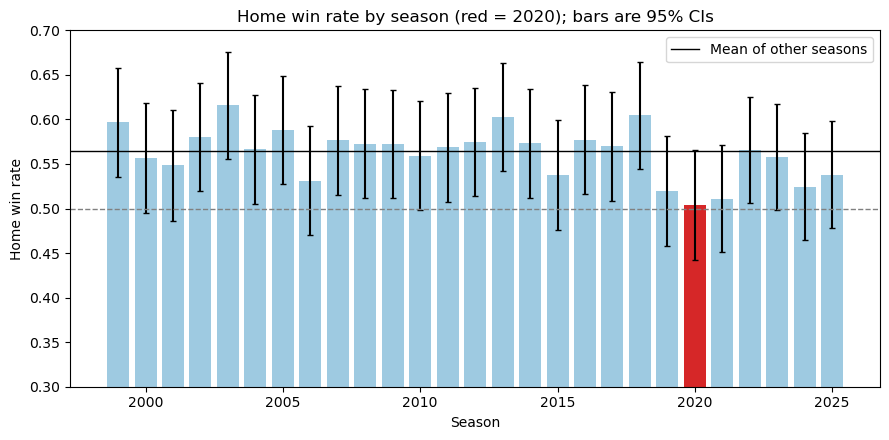

In [3]:
win = compare("home_win_score")
by_season = reg.groupby("season")["home_win_score"].agg(["mean", "sem"])

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#d62728" if s == 2020 else "#9ecae1" for s in by_season.index]
ax.bar(by_season.index, by_season["mean"], yerr=1.96 * by_season["sem"], color=colors, capsize=2)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.axhline(other["home_win_score"].mean(), color="black", linewidth=1, label="Mean of other seasons")
ax.set_ylim(0.3, 0.7)
ax.set_xlabel("Season")
ax.set_ylabel("Home win rate")
ax.set_title("Home win rate by season (red = 2020); bars are 95% CIs")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(fig_dir / "sebastian_covid_home_win_by_season.png", dpi=200)
plt.show()

Each bar is the share of games won by the home team in that season, with ties counted as half a win. The
vertical lines are 95% confidence intervals. The red bar is 2020, the solid line is the average of all other
seasons, and the dashed line is 50%, meaning no home advantage.

In [4]:
season_rates = by_season.drop(index=2020)["mean"]
half_width = (1.96 * by_season["sem"]).mean()
if win["covid"] < season_rates.min():
    season_context = (
        f"2020 has the lowest home win rate of any season, but the lowest of the other seasons "
        f"({season_rates.min():.3f}) is close, and each season's own interval is wide "
        f"(about +/-{half_width:.2f}), so dips of this size from one season to the next are common."
    )
else:
    season_context = (
        f"2020 is not the lowest season: other seasons range from {season_rates.min():.3f} to "
        f"{season_rates.max():.3f}, so a rate like 2020's is not unique to the pandemic year."
    )
lower_higher = "lower" if win["diff"] < 0 else "higher"
gap_pts = abs(win["diff"]) * 100
if win["p"] < 0.05:
    win_answer = (
        f"Yes, the difference is statistically significant. The home win rate was {gap_pts:.1f} percentage "
        f"points {lower_higher} in 2020 and the p-value ({fmt_p(win['p'])}) is below 0.05, so we reject the null "
        f"hypothesis that COVID made no difference. This shows 2020 differed from other seasons. It does not "
        f"show that restricted crowds were the only cause."
    )
else:
    win_answer = (
        f"No, the difference is not statistically significant at the 5% level. The home win rate was "
        f"{gap_pts:.1f} percentage points {lower_higher} in 2020, but the p-value ({fmt_p(win['p'])}) is above 0.05 "
        f"and the confidence interval includes 0, so we cannot conclude that COVID changed the home win rate. "
        f"A non-significant result does not prove there was no effect. With only one COVID season, the test may "
        f"not have enough power to detect one."
    )
conj = "and" if win["p"] < 0.05 else "but"
strength = "strong" if win["p"] < 0.05 else "not conclusive"

display(Markdown(f"""
{win_answer}

The home win rate was {win['covid']:.3f} in 2020 and {win['other']:.3f} in other seasons, a gap of
{win['diff']:+.3f} (95% CI {win['lo']:+.3f} to {win['hi']:+.3f}; t = {win['t']:.2f}, p = {fmt_p(win['p'])}).
The difference is {verdict(win)}.

Home teams won {'less' if win['diff'] < 0 else 'more'} often in 2020, which
{'is consistent with' if win['diff'] < 0 else 'does not fit'} restricted crowds weakening home advantage,
{conj} the evidence is {strength}. {season_context}
"""))


No, the difference is not statistically significant at the 5% level. The home win rate was 6.1 percentage points lower in 2020, but the p-value (0.059) is above 0.05 and the confidence interval includes 0, so we cannot conclude that COVID changed the home win rate. A non-significant result does not prove there was no effect. With only one COVID season, the test may not have enough power to detect one.

The home win rate was 0.504 in 2020 and 0.565 in other seasons, a gap of
-0.061 (95% CI -0.124 to +0.002; t = -1.90, p = 0.059).
The difference is not statistically significant at the 5% level.

Home teams won less often in 2020, which
is consistent with restricted crowds weakening home advantage,
but the evidence is not conclusive. 2020 has the lowest home win rate of any season, but the lowest of the other seasons (0.511) is close, and each season's own interval is wide (about +/-0.06), so dips of this size from one season to the next are common.


### Margin of victory

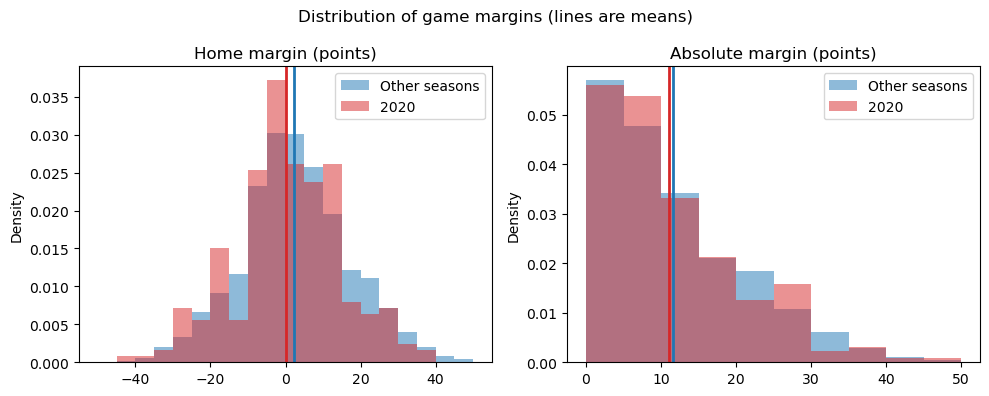

In [5]:
home_m = compare("home_margin")
abs_m = compare("abs_margin")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in [
    (axes[0], "home_margin", "Home margin (points)"),
    (axes[1], "abs_margin", "Absolute margin (points)"),
]:
    bins = range(-50, 51, 5) if metric == "home_margin" else range(0, 51, 5)
    ax.hist(other[metric], bins=bins, density=True, alpha=0.5, color="#1f77b4", label="Other seasons")
    ax.hist(covid[metric], bins=bins, density=True, alpha=0.5, color="#d62728", label="2020")
    ax.axvline(other[metric].mean(), color="#1f77b4", linewidth=2)
    ax.axvline(covid[metric].mean(), color="#d62728", linewidth=2)
    ax.set_title(title)
    ax.set_ylabel("Density")
    ax.legend()
fig.suptitle("Distribution of game margins (lines are means)")
fig.tight_layout()
fig.savefig(fig_dir / "sebastian_covid_margin.png", dpi=200)
plt.show()

The left panel shows the home margin (home points minus away points, positive when the home team wins). The
right panel shows the absolute margin, which ignores who won and measures how lopsided games were. Margin of
victory can mean either, so both are tested. Red is 2020, blue is all other seasons, and the vertical lines
are the averages.

In [6]:
def margin_phrase(res, name):
    if res["p"] < 0.05:
        move = "fell" if res["diff"] < 0 else "rose"
        return f"For {name}, yes: it {move} by {abs(res['diff']):.2f} points (p = {fmt_p(res['p'])})."
    return f"For {name}, no: the change of {res['diff']:+.2f} points is not significant (p = {fmt_p(res['p'])})."


margin_answer = margin_phrase(home_m, "the home margin") + " " + margin_phrase(abs_m, "the absolute margin")
home_text = (
    f"Home teams lost most of their scoring edge in 2020 ({home_m['covid']:+.2f} points on average vs "
    f"{home_m['other']:+.2f})."
    if home_m["p"] < 0.05
    else "Home margins did not change reliably in 2020."
)
abs_text = (
    "Games were about as lopsided as in other seasons."
    if abs_m["p"] >= 0.05
    else "Games also became more or less lopsided."
)

display(Markdown(f"""
{margin_answer}

| Measure | 2020 | Other seasons | Difference | 95% CI | p-value |
|---|---|---|---|---|---|
| Home margin (points) | {home_m['covid']:+.2f} | {home_m['other']:+.2f} | {home_m['diff']:+.2f} | {home_m['lo']:+.2f} to {home_m['hi']:+.2f} | {fmt_p(home_m['p'])} |
| Absolute margin (points) | {abs_m['covid']:.2f} | {abs_m['other']:.2f} | {abs_m['diff']:+.2f} | {abs_m['lo']:+.2f} to {abs_m['hi']:+.2f} | {fmt_p(abs_m['p'])} |

The change in home margin is {verdict(home_m)}. The change in absolute margin is {verdict(abs_m)}.
{home_text} {abs_text}
"""))


For the home margin, yes: it fell by 2.22 points (p = 0.016). For the absolute margin, no: the change of -0.43 points is not significant (p = 0.456).

| Measure | 2020 | Other seasons | Difference | 95% CI | p-value |
|---|---|---|---|---|---|
| Home margin (points) | +0.14 | +2.36 | -2.22 | -4.02 to -0.42 | 0.016 |
| Absolute margin (points) | 11.12 | 11.55 | -0.43 | -1.56 to +0.70 | 0.456 |

The change in home margin is statistically significant at the 5% level. The change in absolute margin is not statistically significant at the 5% level.
Home teams lost most of their scoring edge in 2020 (+0.14 points on average vs +2.36). Games were about as lopsided as in other seasons.


### Robustness check: adding 2021

Some stadiums still had capacity limits early in 2021, so it is a plausible partly restricted season. Without
attendance data we cannot tell which 2021 games were affected, so 2020 stays the main definition. The table
repeats the tests with 2021 added, and with 2021 alone (compared against seasons other than 2020 and 2021).

In [7]:
specs = [
    ("2020 only (main)", (2020,), ()),
    ("2020 + 2021", (2020, 2021), ()),
    ("2021 only", (2021,), (2020,)),
]
outcomes = [
    ("Home win rate", "home_win_score", "{:.3f}", "{:+.3f}"),
    ("Home margin (points)", "home_margin", "{:+.2f}", "{:+.2f}"),
    ("Absolute margin (points)", "abs_margin", "{:.2f}", "{:+.2f}"),
]
results = {}
rows = []
for label, group, exclude in specs:
    for name, metric, f_mean, f_diff in outcomes:
        r = compare(metric, group, exclude)
        results[(label, metric)] = r
        rows.append(
            f"| {label} | {name} | {f_mean.format(r['covid'])} | {f_mean.format(r['other'])} | "
            f"{f_diff.format(r['diff'])} | {f_diff.format(r['lo'])} to {f_diff.format(r['hi'])} | {fmt_p(r['p'])} |"
        )

changed = []
for name, metric, _, _ in outcomes:
    main_sig = results[("2020 only (main)", metric)]["p"] < 0.05
    comb_sig = results[("2020 + 2021", metric)]["p"] < 0.05
    if main_sig != comb_sig:
        changed.append(name.lower())
if changed:
    robust_text = (
        "Adding 2021 changes the conclusion for " + " and ".join(changed) + ", so the result depends on how the "
        "COVID period is defined and should be reported with that caveat."
    )
else:
    robust_text = "Adding 2021 does not change any conclusion."

display(Markdown(f"""
| Group | Outcome | Group mean | Comparison mean | Difference | 95% CI | p-value |
|---|---|---|---|---|---|---|
{chr(10).join(rows)}

{robust_text}
"""))


| Group | Outcome | Group mean | Comparison mean | Difference | 95% CI | p-value |
|---|---|---|---|---|---|---|
| 2020 only (main) | Home win rate | 0.504 | 0.565 | -0.061 | -0.124 to +0.002 | 0.059 |
| 2020 only (main) | Home margin (points) | +0.14 | +2.36 | -2.22 | -4.02 to -0.42 | 0.016 |
| 2020 only (main) | Absolute margin (points) | 11.12 | 11.55 | -0.43 | -1.56 to +0.70 | 0.456 |
| 2020 + 2021 | Home win rate | 0.508 | 0.567 | -0.059 | -0.104 to -0.015 | 0.009 |
| 2020 + 2021 | Home margin (points) | +0.87 | +2.39 | -1.52 | -2.84 to -0.19 | 0.025 |
| 2020 + 2021 | Absolute margin (points) | 11.65 | 11.52 | +0.13 | -0.70 to +0.95 | 0.767 |
| 2021 only | Home win rate | 0.511 | 0.567 | -0.056 | -0.117 to +0.005 | 0.074 |
| 2021 only | Home margin (points) | +1.57 | +2.39 | -0.83 | -2.71 to +1.05 | 0.388 |
| 2021 only | Absolute margin (points) | 12.14 | 11.52 | +0.62 | -0.54 to +1.79 | 0.294 |

Adding 2021 changes the conclusion for home win rate, so the result depends on how the COVID period is defined and should be reported with that caveat.


### Summary

In [8]:
def summary_phrase(res, name):
    word = "significantly lower" if res["diff"] < 0 else "significantly higher"
    if res["p"] < 0.05:
        return f"{name} was {word} in 2020 (p = {fmt_p(res['p'])})"
    return f"{name} did not change significantly in 2020 (p = {fmt_p(res['p'])})"


display(Markdown(
    "Overall, "
    + summary_phrase(win, "the home win rate") + "; "
    + summary_phrase(home_m, "the home margin") + "; "
    + summary_phrase(abs_m, "the absolute margin") + "."
))

Overall, the home win rate did not change significantly in 2020 (p = 0.059); the home margin was significantly lower in 2020 (p = 0.016); the absolute margin did not change significantly in 2020 (p = 0.456).

## Are stadium characteristics associated with stronger home performance?

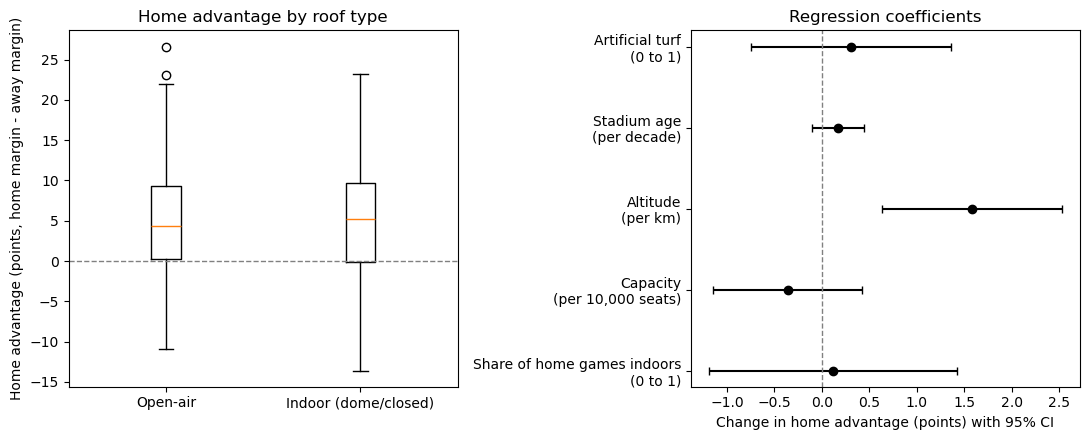

In [9]:
natural = {"grass", "dessograss"}
per_team_season = (
    reg.assign(artificial=(~reg["surface"].isin(natural)).astype(float).where(reg["surface"].notna()))
    .groupby(["home_team", "season"])
    .agg(
        stadium_id=("stadium_id", lambda s: s.mode().iloc[0]),
        indoor_share=("is_indoor", "mean"),
        artificial_share=("artificial", "mean"),
    )
    .reset_index()
    .rename(columns={"home_team": "team"})
)
stad = stadiums[["stadium_id", "capacity", "opened"]]
data = teams.merge(per_team_season, on=["team", "season"]).merge(stad, on="stadium_id", how="left")
data = data[data["season"] != 2020].copy()  # crowds were restricted in 2020
data["capacity_10k"] = data["capacity"] / 10_000
data["age_decades"] = (data["season"] - data["opened"]) / 10
altitude_m = games.groupby("stadium_id")["stadium_altitude_m"].first()
data["altitude_km"] = altitude_m.reindex(data["stadium_id"]).to_numpy() / 1000

model_data = data.dropna(
    subset=["hfa_margin", "indoor_share", "artificial_share", "capacity_10k", "age_decades", "altitude_km"]
)
model = smf.ols(
    "hfa_margin ~ indoor_share + capacity_10k + altitude_km + age_decades + artificial_share",
    data=model_data,
).fit(cov_type="cluster", cov_kwds={"groups": model_data["stadium_id"]})

labels = {
    "indoor_share": "Share of home games indoors (0 to 1)",
    "capacity_10k": "Capacity (per 10,000 seats)",
    "altitude_km": "Altitude (per km)",
    "age_decades": "Stadium age (per decade)",
    "artificial_share": "Artificial turf (0 to 1)",
}
coefs = model.params.drop("Intercept")
ci = model.conf_int().drop("Intercept")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
enclosed = model_data["indoor_share"] > 0.5
axes[0].boxplot(
    [model_data.loc[~enclosed, "hfa_margin"], model_data.loc[enclosed, "hfa_margin"]],
    tick_labels=["Open-air", "Indoor (dome/closed)"],
)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_ylabel("Home advantage (points, home margin - away margin)")
axes[0].set_title("Home advantage by roof type")

y = range(len(coefs))
axes[1].errorbar(coefs, y, xerr=[coefs - ci[0], ci[1] - coefs], fmt="o", color="black", capsize=3)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_yticks(list(y))
axes[1].set_yticklabels([labels[c].replace(" (", "\n(") for c in coefs.index])
axes[1].set_xlabel("Change in home advantage (points) with 95% CI")
axes[1].set_title("Regression coefficients")
fig.tight_layout()
fig.savefig(fig_dir / "sebastian_stadium_traits.png", dpi=200)
plt.show()

The left panel compares home advantage in open-air and indoor stadiums. Home advantage here is a team's average
home margin minus its average away margin in a season, in points. In the right panel, each dot is the
regression's estimated effect of a trait and the line is its 95% confidence interval. A line that crosses the
dashed zero line means the effect cannot be told apart from no effect.

The regression is ordinary least squares and estimates how home advantage changes per unit of each trait while
holding the others fixed. Using each team's away results as the baseline removes team quality, so the outcome
measures how much better a team does at home. Standard errors are clustered by stadium because the same stadium
appears in many seasons. The data has no direct measure of acoustics, so a dome or closed roof stands in for
crowd noise. 2020 is excluded because crowds were restricted.

In [10]:
short = {
    "indoor_share": "indoor roofs", "capacity_10k": "capacity", "altitude_km": "altitude",
    "age_decades": "stadium age", "artificial_share": "artificial turf",
}
sig = [c for c in coefs.index if model.pvalues[c] < 0.05]
nonsig = [c for c in coefs.index if c not in sig]
trait_rows = "\n".join(
    f"| {labels[c]} | {coefs[c]:+.2f} | {ci.loc[c, 0]:+.2f} to {ci.loc[c, 1]:+.2f} | {fmt_p(model.pvalues[c])} |"
    for c in coefs.index
)

if sig:
    sig_list = " and ".join(f"{short[c]} (p = {fmt_p(model.pvalues[c])})" for c in sig)
    stadium_answer = f"Only {sig_list} {'is' if len(sig) == 1 else 'are'} statistically significant. "
    if "indoor_share" not in sig:
        stadium_answer += (
            f"Roof type, our proxy for crowd noise, is not significant (p = {fmt_p(model.pvalues['indoor_share'])}), "
            "so we cannot say indoor stadiums have a different home advantage than open-air ones."
        )
    interp = (
        "Home advantage is reliably linked to " + ", ".join(short[c] for c in sig) + ". "
        + ("A possible explanation is thinner air tiring visiting teams, but this analysis cannot test that. "
           if "altitude_km" in sig else "")
        + ("The other traits (" + ", ".join(short[c] for c in nonsig) + ") show no reliable link. " if nonsig else "")
    )
else:
    stadium_answer = (
        "No, none of the stadium traits is statistically significant. Every confidence interval includes 0, "
        f"including roof type, our proxy for crowd noise (p = {fmt_p(model.pvalues['indoor_share'])})."
    )
    interp = "None of the traits shows a reliable link to home advantage. "

display(Markdown(f"""
{stadium_answer}

The model uses {len(model_data)} team-seasons from {model_data['stadium_id'].nunique()} stadiums
(R-squared = {model.rsquared:.3f}).

| Trait | Effect on home advantage (points) | 95% CI | p-value |
|---|---|---|---|
{trait_rows}

{interp}The low R-squared means these traits explain very little of the season-to-season variation in home
advantage, most of which is chance. {len(data) - len(model_data)} of {len(data)} team-seasons were dropped
because some stadiums have no capacity recorded in the source file.
"""))


Only altitude (p = 0.001) is statistically significant. Roof type, our proxy for crowd noise, is not significant (p = 0.864), so we cannot say indoor stadiums have a different home advantage than open-air ones.

The model uses 623 team-seasons from 43 stadiums
(R-squared = 0.008).

| Trait | Effect on home advantage (points) | 95% CI | p-value |
|---|---|---|---|
| Share of home games indoors (0 to 1) | +0.11 | -1.19 to +1.42 | 0.864 |
| Capacity (per 10,000 seats) | -0.36 | -1.15 to +0.42 | 0.366 |
| Altitude (per km) | +1.58 | +0.63 to +2.53 | 0.001 |
| Stadium age (per decade) | +0.17 | -0.10 to +0.44 | 0.222 |
| Artificial turf (0 to 1) | +0.31 | -0.74 to +1.36 | 0.568 |

Home advantage is reliably linked to altitude. A possible explanation is thinner air tiring visiting teams, but this analysis cannot test that. The other traits (indoor roofs, capacity, stadium age, artificial turf) show no reliable link. The low R-squared means these traits explain very little of the season-to-season variation in home
advantage, most of which is chance. 206 of 829 team-seasons were dropped
because some stadiums have no capacity recorded in the source file.


## Limitations

- 2020 stands in for the COVID period. Attendance varied by team and week, and other things changed that year,
  so crowds cannot be separated from other COVID effects.
- Nothing in the data measures stadium acoustics or design directly. Roof type is a rough proxy.
- Only one season is the main COVID group, so a borderline p-value should be read cautiously.